In [2]:
!pip install scikit-tree

   ---------------------------------------- 0.0/5.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.0 MB 435.7 kB/s eta 0:00:12
   ---------------------------------------- 0.0/5.0 MB 281.8 kB/s eta 0:00:18
    --------------------------------------- 0.1/5.0 MB 476.3 kB/s eta 0:00:11
   - -------------------------------------- 0.1/5.0 MB 607.9 kB/s eta 0:00:09
   - -------------------------------------- 0.2/5.0 MB 541.0 kB/s eta 0:00:10
   - -------------------------------------- 0.2/5.0 MB 724.0 kB/s eta 0:00:07
   - -------------------------------------- 0.2/5.0 MB 600.7 kB/s eta 0:00:08
   -- ------------------------------------- 0.3/5.0 MB 582.4 kB/s eta 0:00:09
   -- ------------------------------------- 0.3/5.0 MB 589.5 kB/s eta 0:00:09
   -- ------------------------------------- 0.3/5.0 MB 589.5 kB/s eta 0:00:09
   -- ------------------------------------- 0.3/5.0 MB 589.5 kB/s eta 0:00:09
   -

In [3]:
import numpy as np
from sktree import ObliqueRandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification

# Generate some example data
X, y = make_classification(n_samples=100, n_features=4,
                           n_informative=2, n_redundant=0,
                           random_state=0, shuffle=False)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

# Create an instance of the ObliqueRandomForestClassifier
# You can adjust parameters like n_estimators (number of trees)
oblique_forest = ObliqueRandomForestClassifier(n_estimators=100, random_state=0)

# Train the model
oblique_forest.fit(X_train, y_train)

# Make predictions
predictions = oblique_forest.predict(X_test)

# Evaluate the model
accuracy = oblique_forest.score(X_test, y_test)
print(f"Model accuracy: {accuracy}")


Model accuracy: 0.8787878787878788


c:\Users\rhodes8\AppData\Local\miniconda3\Lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
c:\Users\rhodes8\AppData\Local\miniconda3\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\rhodes8\AppData\Local\miniconda3\Lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
c:\Users\rhodes8\AppData\Local\miniconda3\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed

c:\Users\rhodes8\AppData\Local\miniconda3\Lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
c:\Users\rhodes8\AppData\Local\miniconda3\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\rhodes8\AppData\Local\miniconda3\Lib\site-packages\sklearn\base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(


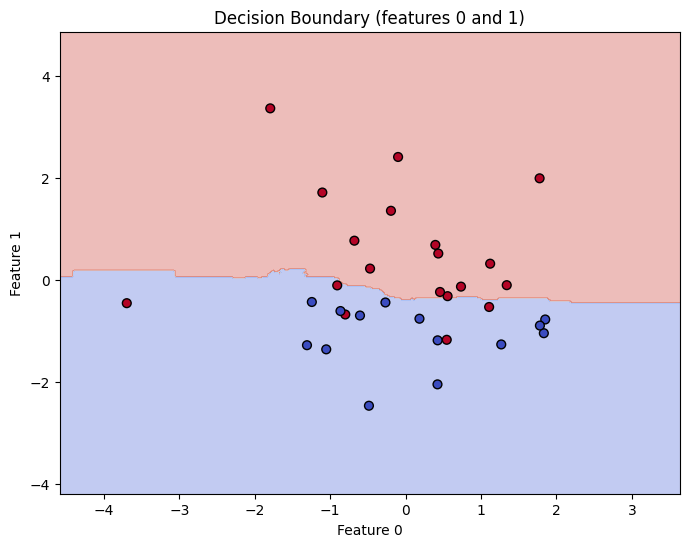

In [4]:
import matplotlib.pyplot as plt

# Plot decision boundary using first two features (fix others to training-set means)
f1, f2 = 0, 1
x_min, x_max = X_train[:, f1].min() - 1.0, X_train[:, f1].max() + 1.0
y_min, y_max = X_train[:, f2].min() - 1.0, X_train[:, f2].max() + 1.0

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

X_grid = np.tile(X_train.mean(axis=0), (xx.size, 1))
X_grid[:, f1] = xx.ravel()
X_grid[:, f2] = yy.ravel()

Z = oblique_forest.predict(X_grid).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.35, cmap="coolwarm")
plt.scatter(
    X_test[:, f1], X_test[:, f2],
    c=y_test, cmap="coolwarm", edgecolor="k", s=40
)
plt.xlabel(f"Feature {f1}")
plt.ylabel(f"Feature {f2}")
plt.title("Decision Boundary (features 0 and 1)")
plt.show()